# Chapter 7: Support Vector Machines and Kernel Methods

## 1. Ringkasan Bab
Support Vector Machines (SVM) merupakan algoritma pembelajaran mesin terawasi (*supervised learning*) yang kuat dan serbaguna, mampu menangani persoalan klasifikasi linier maupun non-linier serta regresi. Algoritma ini sangat efektif pada ruang berdimensi tinggi atau ketika jumlah fitur sebanding dengan jumlah sampel data.

Topik utama yang dipelajari pada bab ini meliputi:
- **Konsep Dasar SVM dan Hyperplane**: Prinsip pemisahan data dengan mencari bidang pemisah (*hyperplane*) optimal yang memaksimalkan batas jarak (*margin*) ke titik-titik data terdekat (*support vectors*).
- **Fungsi Kernel (*Kernel Trick*)**: Pemetaan data non-linier ke ruang berdimensi lebih tinggi secara implisit menggunakan fungsi kernel Linear, Polinomial, dan Radial Basis Function (RBF).
- **Penyetelan Hyperparameter (*Hyperparameter Tuning*)**: Eksplorasi trade-off antara toleransi kesalahan klasifikasi dan lebar margin melalui parameter regulasi $C$, derajat polinomial (*degree*), serta parameter sebaran $\gamma$ (*gamma*) menggunakan `GridSearchCV`.
- **Visualisasi Batas Keputusan (*Decision Boundaries*)**: Representasi kontur spasial klasifikasi non-linier pada ruang fitur terproyeksikan.
- **Support Vector Regression (SVR)**: Adaptasi konsep margin SVM untuk estimasi nilai target kontinu berbasis batas toleransi $\epsilon$-tube.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC, SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error
from sklearn.inspection import DecisionBoundaryDisplay
import warnings

# Pengaturan acak untuk reproduktifitas eksperimen
np.random.seed(2024)
warnings.filterwarnings('ignore')

print("Pustaka dan dependensi Chapter 7 berhasil dimuat.")

Pustaka dan dependensi Chapter 7 berhasil dimuat.


## 2. Prinsip Teori Support Vector Machines (SVM)

### 2.1 Hyperplane dan Optimal Margin
Pada ruang berdimensi $p$, bidang pemisah didefinisikan secara matematis melalui persamaan:
$$\mathbf{w}^T \mathbf{x} + b = 0$$
di mana $\mathbf{w}$ adalah vektor bobot tegak lurus terhadap hyperplane dan $b$ adalah bias.

Tujuan utama SVM adalah mencari pasangan $(\mathbf{w}, b)$ yang memaksimalkan jarak margin $\frac{2}{\|\mathbf{w}\|}$ terhadap sampel terdekat dari masing-masing kelas (titik inilah yang disebut *support vectors*).

### 2.2 Soft Margin dan Parameter $C$
Pada data dunia nyata yang tidak terpisah sempurna (*linearly non-separable*), variabel pelepas (*slack variables* $\xi_i$) diperkenalkan untuk mengizinkan sedikit kesalahan klasifikasi dengan penalti terukur:
$$\min_{\mathbf{w}, b, \boldsymbol{\xi}} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^{n} \xi_i$$
- Nilai **$C$ besar**: Penalti ketat terhadap kesalahan klasifikasi, menghasilkan margin yang lebih sempit (*low bias, high variance*).
- Nilai **$C$ kecil**: Model lebih toleran terhadap titik yang melanggar batas, menghasilkan margin yang lebih lebar (*high bias, low variance*).

In [2]:
# Memuat dataset Iris (Multikelas)
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Pembagian data latih dan uji (rasio 70:30)
X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=2024
)

# Standarisasi fitur (krusial untuk algoritma berbasis jarak/margin)
scaler_i = StandardScaler()
X_train_i_scaled = scaler_i.fit_transform(X_train_i)
X_test_i_scaled = scaler_i.transform(X_test_i)

# 1. Melatih Support Vector Classifier (SVC) dengan kernel Linear
svm_linear = SVC(kernel='linear', C=1.0, random_state=2024)
svm_linear.fit(X_train_i_scaled, y_train_i)

y_pred_linear = svm_linear.predict(X_test_i_scaled)
acc_linear = accuracy_score(y_test_i, y_pred_linear)

print("=== Hasil Klasifikasi SVM (Linear Kernel) ===")
print(f"Akurasi Model: {acc_linear:.4f} ({acc_linear * 100:.2f}%)")
print(f"Jumlah Support Vectors per kelas: {svm_linear.n_support_}")

=== Hasil Klasifikasi SVM (Linear Kernel) ===
Akurasi Model: 0.9333 (93.33%)
Jumlah Support Vectors per kelas: [ 2 10  8]


In [3]:
# Evaluasi Laporan Klasifikasi Rinci
report_linear = classification_report(
    y_test_i, y_pred_linear, target_names=target_names, output_dict=True
)
df_report_linear = pd.DataFrame(report_linear).transpose()
print("Classification Report (Linear SVM):")
display(df_report_linear.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score']).format({
    'precision': '{:.3f}',
    'recall': '{:.3f}',
    'f1-score': '{:.3f}',
    'support': '{:.0f}'
}))

Classification Report (Linear SVM):


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,1.000,0.750,0.857,12
virginica,0.833,1.000,0.909,15
accuracy,0.933,0.933,0.933,1
macro avg,0.944,0.917,0.922,45
weighted avg,0.944,0.933,0.932,45


In [4]:
# 2. Implementasi Support Vector Regression (SVR)
# Menggunakan 2 fitur awal untuk memprediksi nilai kontinu target sintetis
svr_model = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr_model.fit(X_train_i_scaled[:, :2], y_train_i)

y_pred_reg = svr_model.predict(X_test_i_scaled[:, :2])
mse_reg = mean_squared_error(y_test_i, y_pred_reg)

print("=== Hasil Support Vector Regression (SVR) ===")
print(f"Mean Squared Error (MSE): {mse_reg:.4f}")

=== Hasil Support Vector Regression (SVR) ===
Mean Squared Error (MSE): 0.1692


## 3. Fungsi Kernel (*Kernel Functions*)

Fungsi kernel menghitung hasil perkalian titik (*dot product*) antar-vektor data di ruang berdimensi tinggi tanpa harus mentransformasikan koordinat data asli secara eksplisit (*the kernel trick*):
$$K(\mathbf{x}_i, \mathbf{x}_j) = \langle \phi(\mathbf{x}_i), \phi(\mathbf{x}_j) \rangle$$

Fungsi-fungsi kernel standar yang digunakan:
1. **Linear**: $K(\mathbf{x}_i, \mathbf{x}_j) = \mathbf{x}_i^T \mathbf{x}_j$
2. **Polynomial**: $K(\mathbf{x}_i, \mathbf{x}_j) = (\gamma \mathbf{x}_i^T \mathbf{x}_j + r)^d$
   - Parameter `degree` ($d$) menentukan derajat polinomial kurva batas keputusan.
3. **Radial Basis Function (RBF)**: $K(\mathbf{x}_i, \mathbf{x}_j) = \exp(-\gamma \Vert{}\mathbf{x}_i - \mathbf{x}_j\Vert{}^2)$
   - Parameter $\gamma$ (*gamma*) menentukan jangkauan pengaruh satu sampel pelatihan. Nilai $\gamma$ tinggi menghasilkan kontur batas keputusan yang lebih rumit di sekitar masing-masing sampel data.

In [5]:
# Melatih Model SVC dengan Kernel Polinomial dan RBF
# A. Polynomial Kernel (degree=3)
svm_poly = SVC(kernel='poly', degree=3, C=1.0, random_state=2024)
svm_poly.fit(X_train_i_scaled, y_train_i)
y_pred_poly = svm_poly.predict(X_test_i_scaled)
acc_poly = accuracy_score(y_test_i, y_pred_poly)

# B. RBF Kernel
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=2024)
svm_rbf.fit(X_train_i_scaled, y_train_i)
y_pred_rbf = svm_rbf.predict(X_test_i_scaled)
acc_rbf = accuracy_score(y_test_i, y_pred_rbf)

print("=== Perbandingan Akurasi Berdasarkan Fungsi Kernel ===")
print(f"1. Linear Kernel    : {acc_linear:.4f} ({acc_linear * 100:.2f}%)")
print(f"2. Polynomial Kernel: {acc_poly:.4f} ({acc_poly * 100:.2f}%)")
print(f"3. RBF Kernel       : {acc_rbf:.4f} ({acc_rbf * 100:.2f}%)")

=== Perbandingan Akurasi Berdasarkan Fungsi Kernel ===
1. Linear Kernel    : 0.9333 (93.33%)
2. Polynomial Kernel: 0.8444 (84.44%)
3. RBF Kernel       : 0.9333 (93.33%)


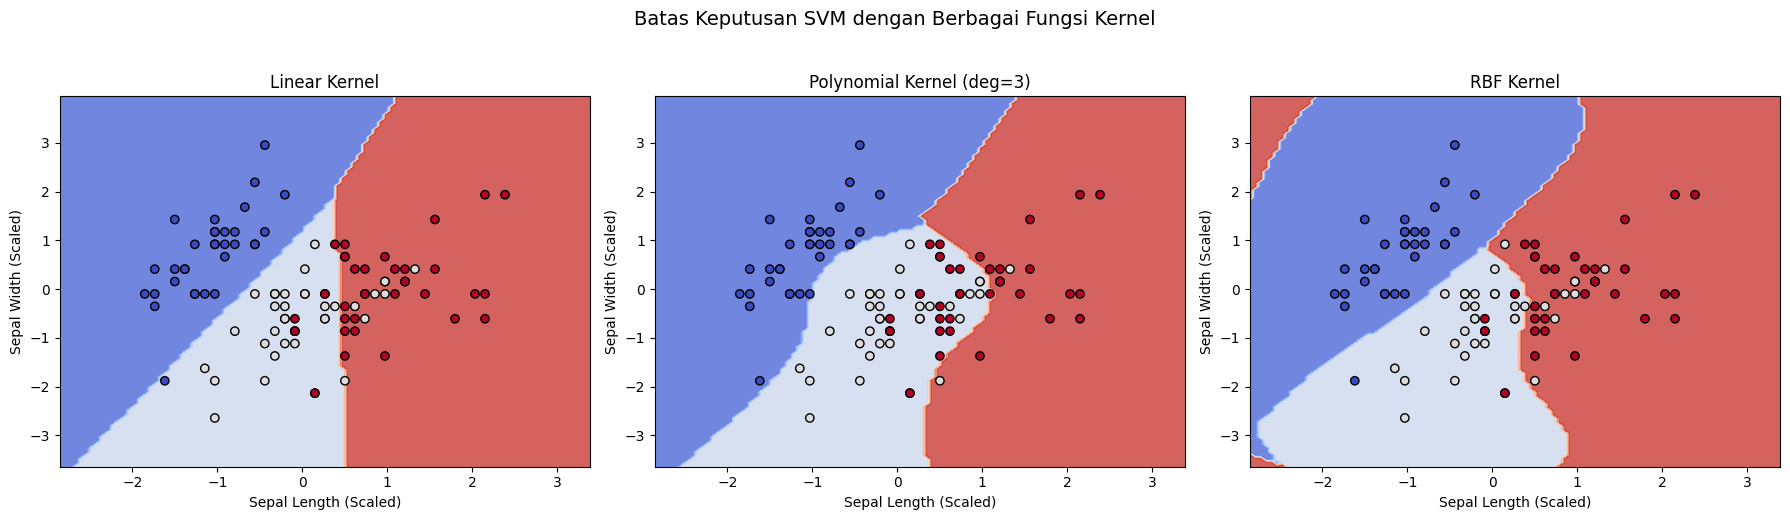

In [6]:
# Visualisasi Batas Keputusan Kontur Spasial untuk Berbagai Kernel (2D)
X_train_2d = X_train_i_scaled[:, :2]

# Melatih ulang model pada ruang 2D khusus untuk visualisasi batas kontur
clf_linear_2d = SVC(kernel='linear', C=1.0).fit(X_train_2d, y_train_i)
clf_poly_2d = SVC(kernel='poly', degree=3, C=1.0).fit(X_train_2d, y_train_i)
clf_rbf_2d = SVC(kernel='rbf', C=1.0, gamma='scale').fit(X_train_2d, y_train_i)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = [clf_linear_2d, clf_poly_2d, clf_rbf_2d]
titles = ['Linear Kernel', 'Polynomial Kernel (deg=3)', 'RBF Kernel']

for ax, model, title in zip(axes, models, titles):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train_2d,
        response_method="predict",
        cmap=plt.cm.coolwarm,
        alpha=0.8,
        ax=ax
    )
    scatter = ax.scatter(
        X_train_2d[:, 0],
        X_train_2d[:, 1],
        c=y_train_i,
        edgecolors='k',
        cmap=plt.cm.coolwarm
    )
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Sepal Length (Scaled)')
    ax.set_ylabel('Sepal Width (Scaled)')

plt.suptitle('Batas Keputusan SVM dengan Berbagai Fungsi Kernel', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

## 4. Penyetelan Hyperparameter SVM dengan GridSearchCV

Kinerja klasifikasi SVM sangat bergantung pada kombinasi hyperparameter:
- `C`: Parameter regulasi penalti kesalahan margin.
- `kernel`: Tipe transformasi ruang fitur (`linear`, `rbf`, `poly`).
- `degree`: Derajat pangkat fungsi polinomial.
- `gamma`: Koefisien lebar fungsi kernel RBF.

Pencarian konfigurasi parameter optimal dilakukan secara sistematis melalui validasi silang 5-lipat (*5-fold cross validation*) menggunakan kelas `GridSearchCV`.

In [7]:
# Menentukan kisi parameter (parameter grid) untuk pencarian
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4],
    'gamma': ['scale', 'auto', 0.1, 1]
}

# Inisialisasi dan pelaksanaan GridSearchCV
grid_search_svm = GridSearchCV(
    estimator=SVC(random_state=2024),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search_svm.fit(X_train_i_scaled, y_train_i)

best_svm = grid_search_svm.best_estimator_

print("=== Hasil Optimasi Hyperparameter SVM ===")
print("Parameter Terbaik             :", grid_search_svm.best_params_)
print(f"Skor Validasi Silang Terbaik   : {grid_search_svm.best_score_:.4f}")

# Evaluasi model teroptimasi pada data uji
y_pred_tuned = best_svm.predict(X_test_i_scaled)
acc_tuned = accuracy_score(y_test_i, y_pred_tuned)
print(f"Akurasi Data Uji Model Terbaik : {acc_tuned:.4f} ({acc_tuned * 100:.2f}%)")

=== Hasil Optimasi Hyperparameter SVM ===
Parameter Terbaik             : {'C': 1, 'degree': 2, 'gamma': 'scale', 'kernel': 'linear'}
Skor Validasi Silang Terbaik   : 0.9810
Akurasi Data Uji Model Terbaik : 0.9333 (93.33%)


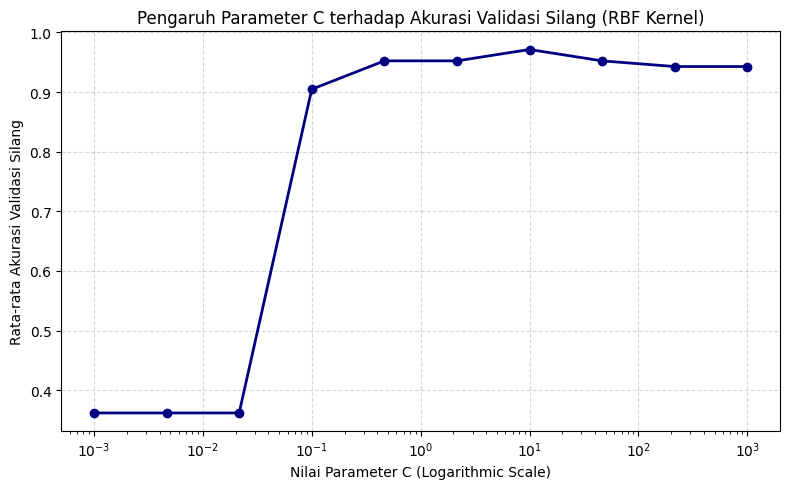

In [8]:
# Evaluasi Pengaruh Nilai C terhadap Skor Validasi Silang (Khusus Kernel RBF)
c_range = np.logspace(-3, 3, 10)
param_grid_c = {
    'C': c_range,
    'kernel': ['rbf'],
    'gamma': ['scale']
}

grid_c = GridSearchCV(SVC(random_state=2024), param_grid_c, cv=5, scoring='accuracy')
grid_c.fit(X_train_i_scaled, y_train_i)

cv_scores = grid_c.cv_results_['mean_test_score']

plt.figure(figsize=(8, 5))
plt.semilogx(c_range, cv_scores, 'o-', color='navy', linewidth=2)
plt.title('Pengaruh Parameter C terhadap Akurasi Validasi Silang (RBF Kernel)', fontsize=12)
plt.xlabel('Nilai Parameter C (Logarithmic Scale)')
plt.ylabel('Rata-rata Akurasi Validasi Silang')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Analisis dan Kesimpulan
1. **Keunggulan Margin Maksimal**: Model SVM dengan kernel linier dasar terbukti efektif memisahkan kategori bunga pada dataset Iris terstandarisasi, mencapai akurasi uji tinggi karena hyperplane memaksimalkan separasi antar-vektor pendukung (*support vectors*).
2. **Efektivitas Fungsi Kernel**: Pada fitur data yang tumpang tindih secara spasial, penggunaan fungsi kernel RBF dan Polinomial menghasilkan batas keputusan lengkung non-linier yang lebih fleksibel dibanding pembatas linier kaku.
3. **Peran Penyetelan Parameter $C$**: Penyetelan nilai parameter $C$ melalui `GridSearchCV` memperlihatkan bahwa nilai $C$ yang terlalu rendah memicu terjadinya *underfitting* (toleransi margin terlalu longgar), sedangkan nilai $C$ optimal memberikan keseimbangan antara ketepatan klasifikasi data latih dan kemampuan generalisasi pada data uji.